In [1]:
import torch
import matplotlib.pyplot as plt

In [2]:
device = "cuda" if torch.cuda.is_available() else "cpu"
device

'cpu'

In [3]:
w = 0.3
b = 0.9

start = 0
end = 1
step = 0.01


dataset = torch.arange(start, end, step).unsqueeze(dim=1)
result = w * dataset + b

print(dataset.shape)
print(result.shape)
print(" ")
print(dataset[:10])
print(" ")
print(result[:10])
print(" ")
print(len(dataset))
print(len(result))



torch.Size([100, 1])
torch.Size([100, 1])
 
tensor([[0.0000],
        [0.0100],
        [0.0200],
        [0.0300],
        [0.0400],
        [0.0500],
        [0.0600],
        [0.0700],
        [0.0800],
        [0.0900]])
 
tensor([[0.9000],
        [0.9030],
        [0.9060],
        [0.9090],
        [0.9120],
        [0.9150],
        [0.9180],
        [0.9210],
        [0.9240],
        [0.9270]])
 
100
100


In [4]:
# split the data

split = int(len(dataset)* 0.8)
train_dataset = dataset[:split]
train_result = result[:split]

test_dataset = dataset[split:]
test_result = result[split:]

print(train_dataset.shape)
print(train_result.shape)
print(" ")
print(test_dataset.shape)
print(test_result.shape)
print(" ")
print(len(train_dataset))
print(len(train_result))
print(" ")
print(len(test_dataset))
print(len(test_result))

torch.Size([80, 1])
torch.Size([80, 1])
 
torch.Size([20, 1])
torch.Size([20, 1])
 
80
80
 
20
20


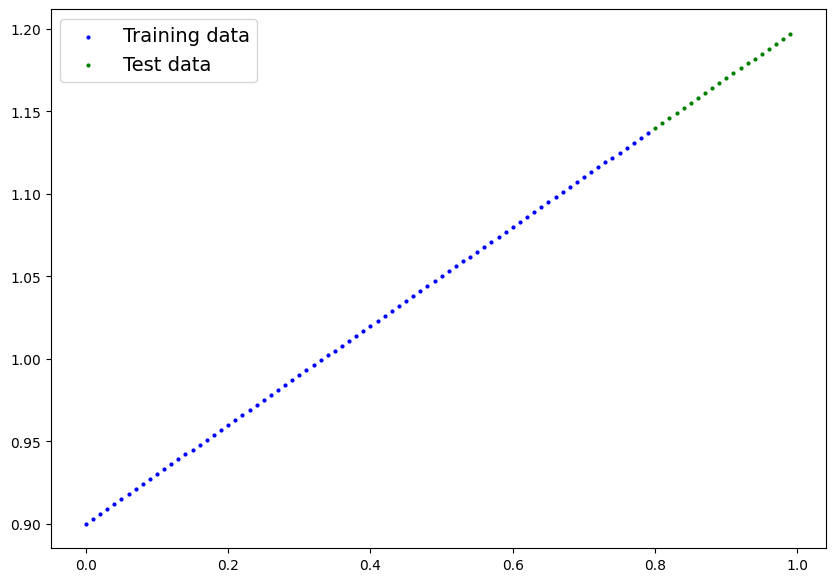

In [12]:
# plot the data

def plot_predictions (train_dataset=train_dataset,
                      train_result=train_result,
                      test_dataset=test_dataset,
                      test_result=test_result,
                      prediction=None):

  plt.figure(figsize = (10,7))
  plt.scatter(train_dataset,train_result,c = 'b',s = 4,label = "Training data")
  plt.scatter(test_dataset,test_result,c = 'g',s = 4,label = "Test data")

  if prediction is not None:
    plt.scatter(test_dataset,prediction,c = 'r',s = 4,label = "Predictions")
  plt.legend(prop = {"size" : 14})
plot_predictions()


In [6]:
# Build the model
from torch import nn
class LinearRegressionModel(nn.Module):

  def __init__(self):
    super().__init__()

    self.weights = nn.Parameter(data=torch.randn(1,
                                            dtype=float,
                                            requires_grad=True))
    self.bias = nn.Parameter(data=torch.randn(1,
                                         dtype=float,
                                         requires_grad=True))


  def forward(self, x):
    return self.weights * x + self.bias

torch.manual_seed(42)
model_1 = LinearRegressionModel()
model_1, model_1.state_dict()




(LinearRegressionModel(),
 OrderedDict([('weights', tensor([0.3367], dtype=torch.float64)),
              ('bias', tensor([0.1288], dtype=torch.float64))]))

In [7]:
next(model_1.parameters()).to(device)

Parameter containing:
tensor([0.3367], dtype=torch.float64, requires_grad=True)

In [8]:
# create a loss function

loss_fn = nn.L1Loss()

# create an optimizer

optimizer = torch.optim.SGD(params = model_1.parameters(),
                           lr=0.01)


In [9]:
# setup a training loop

torch.manual_seed(42)

epochs = 300



for epoch in range(epochs):
  model_1.train()
  y_pred = model_1(train_dataset)
  loss = loss_fn(y_pred,train_result)
  optimizer.zero_grad()
  loss.backward()
  optimizer.step()


  if epoch % 10 == 0:
      model_1.eval()                      # pas d'affectation
      with torch.inference_mode():
          test_pred = model_1(test_dataset)
          test_loss = loss_fn(test_pred, test_result)    # test_pred, pas y_preds
      print(f"Epoch: {epoch} | Train loss: {loss:.5f} | Test loss: {test_loss:.5f}")

Epoch: 0 | Train loss: 0.75670 | Test loss: 0.72482
Epoch: 10 | Train loss: 0.64110 | Test loss: 0.58946
Epoch: 20 | Train loss: 0.52549 | Test loss: 0.45411
Epoch: 30 | Train loss: 0.40989 | Test loss: 0.31876
Epoch: 40 | Train loss: 0.29429 | Test loss: 0.18341
Epoch: 50 | Train loss: 0.17869 | Test loss: 0.04805
Epoch: 60 | Train loss: 0.07659 | Test loss: 0.07274
Epoch: 70 | Train loss: 0.05744 | Test loss: 0.11017
Epoch: 80 | Train loss: 0.05255 | Test loss: 0.11582
Epoch: 90 | Train loss: 0.04898 | Test loss: 0.11233
Epoch: 100 | Train loss: 0.04554 | Test loss: 0.10468
Epoch: 110 | Train loss: 0.04212 | Test loss: 0.09703
Epoch: 120 | Train loss: 0.03869 | Test loss: 0.08938
Epoch: 130 | Train loss: 0.03526 | Test loss: 0.08174
Epoch: 140 | Train loss: 0.03183 | Test loss: 0.07409
Epoch: 150 | Train loss: 0.02841 | Test loss: 0.06644
Epoch: 160 | Train loss: 0.02498 | Test loss: 0.05810
Epoch: 170 | Train loss: 0.02156 | Test loss: 0.05011
Epoch: 180 | Train loss: 0.01813 | Test

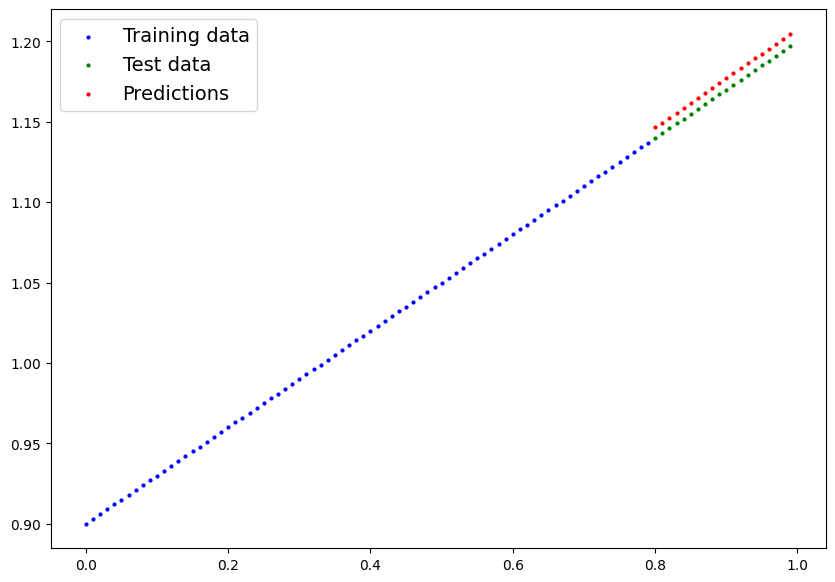

In [13]:
# Make predictions with Model_1

model_1.eval()

with torch.inference_mode():
  y_preds = model_1(test_dataset)

plot_predictions(prediction=y_preds)

In [20]:
# Save model_1 (not from memory)

from pathlib import Path

MODEL_PATH = Path("models")
MODEL_PATH.mkdir(parents=True, exist_ok=True)

MODEL_NAME = "model_1_from_head.pth"
MODEL_SAVE_PATH = MODEL_PATH / MODEL_NAME

torch.save(obj=model_1.state_dict(),
           f=MODEL_SAVE_PATH)





In [18]:
loaded_model = LinearRegressionModel()
loaded_model.load_state_dict(torch.load(f = MODEL_SAVE_PATH))
loaded_model.to(device)

LinearRegressionModel()

In [19]:
y_preds_new = loaded_model(test_dataset)
y_preds == y_preds_new

tensor([[True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True]])